<a href="https://colab.research.google.com/github/carolyndevadoss/MMA3001-Project/blob/main/examples/MMA3001_Temperature_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# MMA3001  Numerical Methods and Machine Learning

## Short Term Indoor Temperature Prediction Using Smart Building Sensor Data

### Project Objective

This project investigates the accuracy and computational performance of machine learning methods for predicting indoor temperature 30 minutes in advance.

The project uses environmental sensor measurements from the Monash Smart Infrastructure Occupancy and Environmental Dataset.

### Engineering Problem

Accurately predicting short-term indoor temperature changes may assist building environmental monitoring and support more responsive HVAC control strategies.

The objective is to evaluate whether machine learning methods can outperform a simple persistence prediction when using historical indoor temperature measurements.

### Computational Methods

The following approaches are investigated:

1. Persistence baseline
2. Simple linear regression
3. Historical linear regression
4. Decision Tree regression
5. Random Forest regression

### Evaluation Criteria

Models are compared using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Computational training time
- Model complexity and generalisation

A chronological training, validation and testing strategy is used to reduce information leakage.

### Dataset Limitations

The dataset contains irregular sampling intervals, repeated records and missing historical measurements. These limitations are investigated during preprocessing and considered when interpreting model performance.


## 1. Import Libraries

The following libraries are used for data processing,
numerical calculations, visualisation and machine learning.

In [27]:
#Import required libraries

# Data processing
import pandas as pd
import numpy as np
import json
import glob
import time

# Data visualisation
import matplotlib.pyplot as plt

# Machine learning models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Model evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("All required libraries imported successfully.")


All required libraries imported successfully.


In [28]:
# Find CSV files uploaded to Colab
csv_files = glob.glob("/content/*.csv")
print("Available CSV files:", csv_files)

# Load the environmental dataset
df = pd.read_csv(csv_files[0], low_memory=False)

# Check the dataset structure
print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

# Display the first five rows
display(df.head())

Available CSV files: ['/content/5EnvSensor_MayToDec2024_180kRows.csv']

Dataset shape: (179447, 8)

Column names: ['id', 'sensorid', 'devicetype', 'jsondata', 'status', 'processing_errors', 'createdate', 'processdate']


,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
0,2,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 03:11:58.210358+11,2024-02-29 03:11:58.210358+11
1,4,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:08.833822+11,2024-02-29 17:09:08.833822+11
2,5,6012002000326,env,"[{""values"": [{""time"": 1702270857, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:12.444245+11,2024-02-29 17:09:12.444245+11
3,16,6012002000777,env,"[{""values"": [{""time"": 1683326565, ""value"": 4.1...",Processed,NaN,2024-02-29 17:10:24.443407+11,2024-02-29 17:10:24.443407+11
4,24,6012002000869,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11


In [29]:
# Decode the first environmental sensor record
sample = df["jsondata"].dropna().iloc[0]
parsed = json.loads(sample)

# Identify the environmental variables available
print("Number of measurement groups:", len(parsed))

for i, group in enumerate(parsed):
    variable = group["variable"]

    print(
        f"{i+1}. {variable['name']} "
        f"({variable['unit']})"
    )

Number of measurement groups: 11
1. Battery (V)
2. Carbon dioxide (ppm)
3. Humidity (HR%)
4. Formaldehyde (µg/m3)
5. Pressure (mb)
6. Temperature (°C)
7. Light Volatile Organic Compounds (ppb)
8. Particulate matter 1 (µg/m3)
9. Particulate matter 4 (µg/m3)
10. Particulate matter 2.5 (µg/m3)
11. Particulate matter 10 (µg/m3)


In [30]:
# Extract temperature measurements from the full dataset
temperature_readings = []

for _, row in df.iterrows():
    if pd.isna(row["jsondata"]):
        continue

    try:
        groups = json.loads(row["jsondata"])

        for group in groups:
            if group["variable"]["name"] == "Temperature":
                for reading in group["values"]:
                    temperature_readings.append({
                        "sensorid": str(row["sensorid"]),
                        "timestamp": reading["time"],
                        "temperature_C": reading["value"]
                    })

    except (json.JSONDecodeError, KeyError, TypeError):
        continue

# Create a DataFrame
temp_all = pd.DataFrame(temperature_readings)

# Convert Unix timestamps into UTC datetime
temp_all["timestamp"] = pd.to_datetime(
    temp_all["timestamp"],
    unit="s",
    utc=True
)

# Display dataset information
print("Total extracted readings:", len(temp_all))
print("Unique sensors:", temp_all["sensorid"].nunique())
print("Date range:", temp_all["timestamp"].min(),
      "to", temp_all["timestamp"].max())

display(temp_all.head())


Total extracted readings: 179447
Unique sensors: 5
Date range: 2023-05-05 22:42:45+00:00 to 2026-04-22 13:12:41+00:00


,sensorid,timestamp,temperature_C
0,6012002000241,2023-12-11 05:52:45+00:00,23.8
1,6012002000241,2023-12-11 05:52:45+00:00,23.8
2,6012002000326,2023-12-11 05:00:57+00:00,23.8
3,6012002000777,2023-05-05 22:42:45+00:00,18.8
4,6012002000869,2024-02-29 06:04:56+00:00,24.3


In [31]:
# Count exact duplicate measurements
duplicates = temp_all.duplicated(
    subset=["sensorid", "timestamp", "temperature_C"]
).sum()

print("Total readings:", len(temp_all))
print("Exact duplicates:", duplicates)

# Remove exact duplicates and sort chronologically
temp_clean = (
    temp_all
    .drop_duplicates(
        subset=["sensorid", "timestamp", "temperature_C"]
    )
    .sort_values(["sensorid", "timestamp"])
    .reset_index(drop=True)
)

print("Readings after removing duplicates:", len(temp_clean))

# Summarise readings for each sensor
sensor_summary = (
    temp_clean.groupby("sensorid")
    .agg(
        readings=("temperature_C", "size"),
        first_reading=("timestamp", "min"),
        last_reading=("timestamp", "max")
    )
)

# Calculate intervals between consecutive measurements
temp_clean["interval_minutes"] = (
    temp_clean.groupby("sensorid")["timestamp"]
    .diff()
    .dt.total_seconds() / 60
)

# Find the median sampling interval for each sensor
sensor_summary["median_interval_minutes"] = (
    temp_clean.groupby("sensorid")["interval_minutes"]
    .median()
)

display(sensor_summary)


Total readings: 179447
Exact duplicates: 136604
Readings after removing duplicates: 42843


,readings,first_reading,last_reading,median_interval_minutes
sensorid,,,,
6012002000227,1,2023-12-11 05:07:53+00:00,2023-12-11 05:07:53+00:00,NaN
6012002000241,2,2023-12-11 05:52:45+00:00,2025-05-19 13:08:04+00:00,756435.316667
6012002000326,29039,2023-12-11 05:00:57+00:00,2026-04-22 13:12:41+00:00,10.000000
6012002000777,1,2023-05-05 22:42:45+00:00,2023-05-05 22:42:45+00:00,NaN
6012002000869,13800,2024-02-29 06:04:56+00:00,2024-06-13 17:45:44+00:00,10.000000


Selected sensor: 6012002000869
Number of readings: 13800

Temperature statistics:
count    13800.000000
mean        23.089514
std          1.163156
min         19.000000
25%         22.500000
50%         23.300000
75%         23.800000
max         28.500000
Name: temperature_C, dtype: float64

Sampling interval statistics:
count    13799.000000
mean        11.008102
std          3.013253
min          9.566667
25%         10.000000
50%         10.000000
75%         10.000000
max         29.983333
Name: interval_minutes, dtype: float64

Gaps greater than 30 minutes: 0


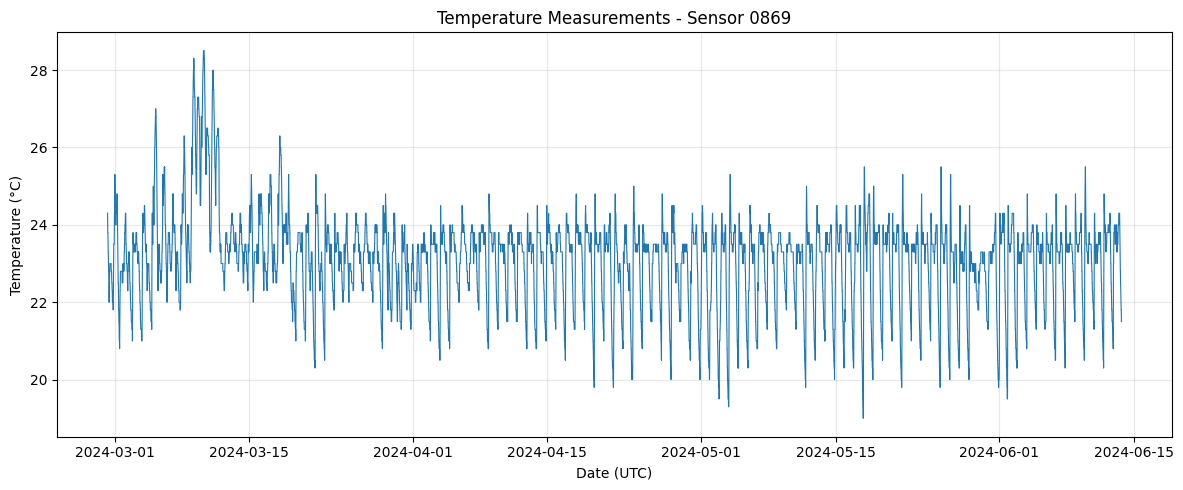

In [32]:

# STEP 7: Select and analyse the project sensor

# Explicitly select sensor 0869
selected_sensor = "6012002000869"

sensor_df = (
    temp_clean[
        temp_clean["sensorid"].astype(str) == selected_sensor
    ]
    .copy()
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Calculate sampling intervals
sensor_df["interval_minutes"] = (
    sensor_df["timestamp"]
    .diff()
    .dt.total_seconds()
    .div(60)
)

# Verify selected sensor
print("Selected sensor:", selected_sensor)
print("Number of readings:", len(sensor_df))

# Temperature statistics
print("\nTemperature statistics:")
print(sensor_df["temperature_C"].describe())

# Sampling interval statistics
print("\nSampling interval statistics:")
print(sensor_df["interval_minutes"].describe())

print("\nGaps greater than 30 minutes:",
      (sensor_df["interval_minutes"] > 30).sum())

# Plot temperature over time
plt.figure(figsize=(12, 5))
plt.plot(
    sensor_df["timestamp"],
    sensor_df["temperature_C"],
    linewidth=0.8
)

plt.title("Temperature Measurements - Sensor 0869")
plt.xlabel("Date (UTC)")
plt.ylabel("Temperature (°C)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



Intervals approximately 10 minutes: 12409
Intervals approximately 20 minutes: 1389
Other intervals: 1

Duplicate timestamps: 0


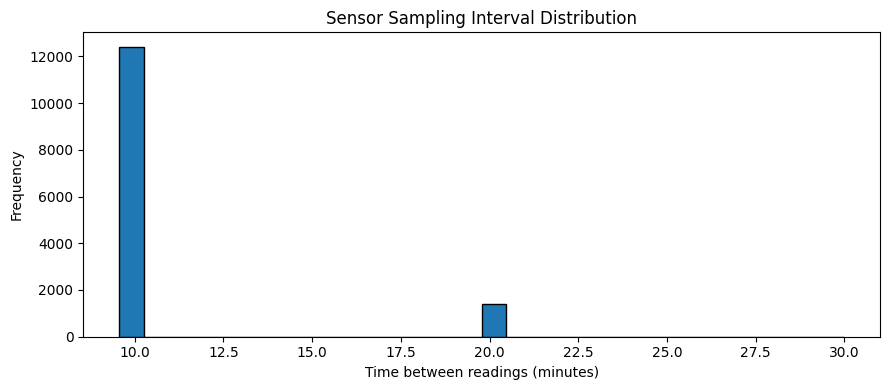

In [33]:
intervals = sensor_df["interval_minutes"].dropna()

print("Intervals approximately 10 minutes:",
      intervals.between(9.5, 10.5).sum())

print("Intervals approximately 20 minutes:",
      intervals.between(19.5, 20.5).sum())

print("Other intervals:",
      (~intervals.between(9.5, 10.5) &
       ~intervals.between(19.5, 20.5)).sum())

# Check whether timestamps are unique
print("\nDuplicate timestamps:",
      sensor_df["timestamp"].duplicated().sum())

# Plot distribution of sampling intervals
plt.figure(figsize=(9, 4))
plt.hist(intervals, bins=30, edgecolor="black")
plt.xlabel("Time between readings (minutes)")
plt.ylabel("Frequency")
plt.title("Sensor Sampling Interval Distribution")
plt.tight_layout()
plt.show()


In [34]:
# Start with our cleaned, selected sensor data
model_df = sensor_df[
    ["timestamp", "temperature_C"]
].copy().sort_values("timestamp")

# Create the target timestamps
model_df["target_time"] = (
    model_df["timestamp"] + pd.Timedelta(minutes=30)
)

# Prepare actual future temperature measurements
future_df = model_df[
    ["timestamp", "temperature_C"]
].rename(columns={
    "timestamp": "actual_time",
    "temperature_C": "target_temperature_C"
})

# Match each target time to the nearest actual reading
model_df = pd.merge_asof(
    model_df.sort_values("target_time"),
    future_df.sort_values("actual_time"),
    left_on="target_time",
    right_on="actual_time",
    direction="nearest",
    tolerance=pd.Timedelta(minutes=2)
)

# Keep only observations with a valid future target
model_df = model_df.dropna(
    subset=["target_temperature_C"]
).sort_values("timestamp").reset_index(drop=True)

# Verify the actual prediction horizon
model_df["horizon_minutes"] = (
    model_df["actual_time"] - model_df["timestamp"]
).dt.total_seconds() / 60

print("Valid prediction samples:", len(model_df))
print("\nActual prediction horizons:")
print(model_df["horizon_minutes"].describe())

display(model_df.head(10))


Valid prediction samples: 12428

Actual prediction horizons:
count    12428.000000
mean        30.000161
std          0.016444
min         29.566667
25%         30.000000
50%         30.000000
75%         30.000000
max         30.350000
Name: horizon_minutes, dtype: float64


,timestamp,temperature_C,target_time,actual_time,target_temperature_C,horizon_minutes
0,2024-02-29 06:04:56+00:00,24.3,2024-02-29 06:34:56+00:00,2024-02-29 06:34:57+00:00,23.8,30.016667
1,2024-02-29 06:14:57+00:00,24.0,2024-02-29 06:44:57+00:00,2024-02-29 06:44:57+00:00,23.8,30.000000
2,2024-02-29 06:44:57+00:00,23.8,2024-02-29 07:14:57+00:00,2024-02-29 07:14:57+00:00,23.5,30.000000
3,2024-02-29 06:54:57+00:00,23.8,2024-02-29 07:24:57+00:00,2024-02-29 07:24:57+00:00,23.3,30.000000
4,2024-02-29 07:24:57+00:00,23.3,2024-02-29 07:54:57+00:00,2024-02-29 07:54:57+00:00,23.3,30.000000
5,2024-02-29 07:34:57+00:00,23.3,2024-02-29 08:04:57+00:00,2024-02-29 08:04:57+00:00,23.0,30.000000
6,2024-02-29 08:04:57+00:00,23.0,2024-02-29 08:34:57+00:00,2024-02-29 08:34:56+00:00,22.8,29.983333
7,2024-02-29 08:14:57+00:00,23.0,2024-02-29 08:44:57+00:00,2024-02-29 08:44:56+00:00,22.8,29.983333
8,2024-02-29 08:44:56+00:00,22.8,2024-02-29 09:14:56+00:00,2024-02-29 09:14:55+00:00,22.5,29.983333
9,2024-02-29 08:54:56+00:00,22.8,2024-02-29 09:24:56+00:00,2024-02-29 09:24:55+00:00,22.3,29.983333


In [35]:
# Sort observations chronologically
model_df = model_df.sort_values("timestamp").reset_index(drop=True)

# Divide observations into 80% training and 20% testing
split_index = int(len(model_df) * 0.8)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

# Remove training examples whose targets overlap the test period
test_start = test_df["timestamp"].min()

train_df = train_df[
    train_df["actual_time"] < test_start
].copy()

# Persistence baseline
test_df["baseline_prediction"] = test_df["temperature_C"]

# Evaluate the baseline
baseline_mae = mean_absolute_error(
    test_df["target_temperature_C"],
    test_df["baseline_prediction"]
)

baseline_rmse = np.sqrt(mean_squared_error(
    test_df["target_temperature_C"],
    test_df["baseline_prediction"]
))

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))
print("Training target ends:", train_df["actual_time"].max())
print("Testing begins:", test_start)

print(f"\nBaseline MAE: {baseline_mae:.4f} °C")
print(f"Baseline RMSE: {baseline_rmse:.4f} °C")

Training samples: 9940
Testing samples: 2486
Training target ends: 2024-05-24 21:25:35+00:00
Testing begins: 2024-05-24 21:35:35+00:00

Baseline MAE: 0.2039 °C
Baseline RMSE: 0.4000 °C


In [36]:
# Define training and testing inputs
X_train = train_df[["temperature_C"]]
y_train = train_df["target_temperature_C"]

X_test = test_df[["temperature_C"]]
y_test = test_df["target_temperature_C"]

# Create and train the model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict future temperatures
linear_predictions = linear_model.predict(X_test)

# Evaluate prediction accuracy
linear_mae = mean_absolute_error(y_test, linear_predictions)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

# Compare with the baseline
print("PERSISTENCE BASELINE")
print(f"MAE:  {baseline_mae:.4f} °C")
print(f"RMSE: {baseline_rmse:.4f} °C")

print("\nLINEAR REGRESSION")
print(f"MAE:  {linear_mae:.4f} °C")
print(f"RMSE: {linear_rmse:.4f} °C")

print("\nMODEL COEFFICIENTS")
print(f"Slope: {linear_model.coef_[0]:.4f}")
print(f"Intercept: {linear_model.intercept_:.4f}")


PERSISTENCE BASELINE
MAE:  0.2039 °C
RMSE: 0.4000 °C

LINEAR REGRESSION
MAE:  0.2193 °C
RMSE: 0.3946 °C

MODEL COEFFICIENTS
Slope: 0.9614
Intercept: 0.8899


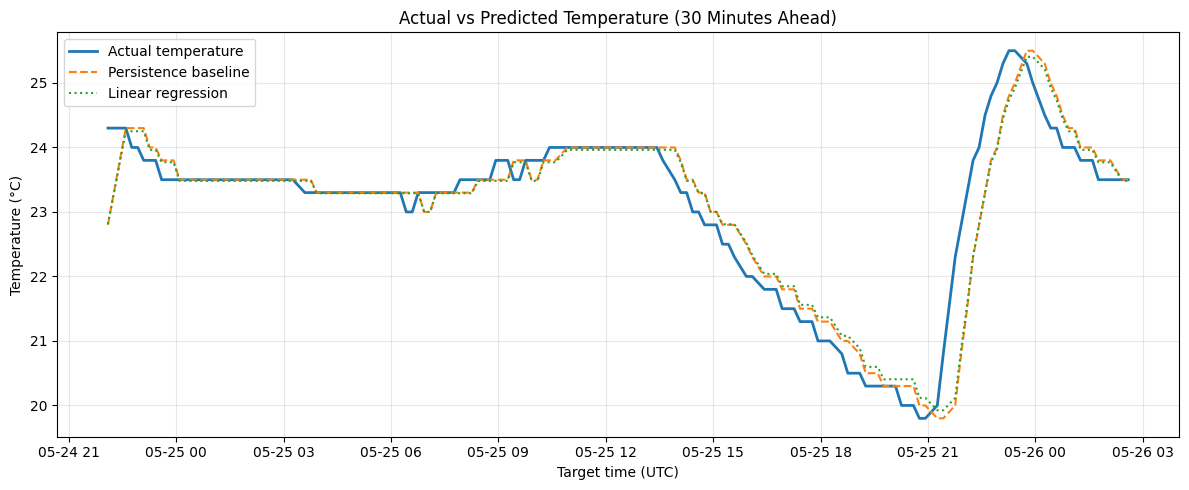

In [37]:
# Show the first 150 test predictions
n = 150

plt.figure(figsize=(12, 5))

plt.plot(
    test_df["actual_time"].iloc[:n],
    y_test.iloc[:n],
    label="Actual temperature",
    linewidth=2
)

plt.plot(
    test_df["actual_time"].iloc[:n],
    test_df["baseline_prediction"].iloc[:n],
    label="Persistence baseline",
    linestyle="--"
)

plt.plot(
    test_df["actual_time"].iloc[:n],
    linear_predictions[:n],
    label="Linear regression",
    linestyle=":"
)

plt.title("Actual vs Predicted Temperature (30 Minutes Ahead)")
plt.xlabel("Target time (UTC)")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [38]:
# Start with our existing prediction dataset
features_df = model_df.copy().sort_values("timestamp")

# Historical readings from the original cleaned sensor data
history_df = (
    sensor_df[["timestamp", "temperature_C"]]
    .sort_values("timestamp")
    .copy()
)

# Add temperature readings from 10, 20 and 30 minutes ago
for minutes in [10, 20, 30]:

    # Calculate the timestamp we want to find
    lookback_col = f"lookback_{minutes}min"
    feature_col = f"temp_{minutes}min_ago"

    features_df[lookback_col] = (
        features_df["timestamp"]
        - pd.Timedelta(minutes=minutes)
    )

    # Prepare historical measurements
    past_df = history_df.rename(columns={
        "timestamp": f"past_time_{minutes}",
        "temperature_C": feature_col
    })

    # Match to a measurement near the desired past time
    features_df = pd.merge_asof(
        features_df.sort_values(lookback_col),
        past_df.sort_values(f"past_time_{minutes}"),
        left_on=lookback_col,
        right_on=f"past_time_{minutes}",
        direction="nearest",
        tolerance=pd.Timedelta(minutes=2)
    )

# Restore chronological order
features_df = features_df.sort_values(
    "timestamp"
).reset_index(drop=True)

# Check feature availability
feature_columns = [
    "temperature_C",
    "temp_10min_ago",
    "temp_20min_ago",
    "temp_30min_ago"
]

print("Total prediction samples:", len(features_df))

print("\nMissing historical measurements:")
print(features_df[feature_columns].isna().sum())

print("\nFirst 10 rows:")
display(
    features_df[
        ["timestamp"] + feature_columns +
        ["target_temperature_C"]
    ].head(10)
)

Total prediction samples: 12428

Missing historical measurements:
temperature_C        0
temp_10min_ago    1011
temp_20min_ago    1343
temp_30min_ago    1368
dtype: int64

First 10 rows:


,timestamp,temperature_C,temp_10min_ago,temp_20min_ago,temp_30min_ago,target_temperature_C
0,2024-02-29 06:04:56+00:00,24.3,NaN,NaN,NaN,23.8
1,2024-02-29 06:14:57+00:00,24.0,24.3,NaN,NaN,23.8
2,2024-02-29 06:44:57+00:00,23.8,23.8,NaN,24.0,23.5
3,2024-02-29 06:54:57+00:00,23.8,23.8,23.8,NaN,23.3
4,2024-02-29 07:24:57+00:00,23.3,23.5,NaN,23.8,23.3
5,2024-02-29 07:34:57+00:00,23.3,23.3,23.5,NaN,23.0
6,2024-02-29 08:04:57+00:00,23.0,23.3,NaN,23.3,22.8
7,2024-02-29 08:14:57+00:00,23.0,23.0,23.3,NaN,22.8
8,2024-02-29 08:44:56+00:00,22.8,22.8,NaN,23.0,22.5
9,2024-02-29 08:54:56+00:00,22.8,22.8,22.8,NaN,22.3


In [39]:
# Select observations with all historical temperatures available
features_clean = (
    features_df
    .dropna(subset=feature_columns)
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print("Original prediction samples:", len(features_df))
print("Complete-feature samples:", len(features_clean))
print("Samples excluded:", len(features_df) - len(features_clean))

# Preserve the original chronological test boundary
test_start = test_df["timestamp"].min()

# Training: samples before the test period whose targets
# do not overlap the test period
feature_train = features_clean[
    features_clean["actual_time"] < test_start
].copy()

# Testing: only samples from the original test period
feature_test = features_clean[
    features_clean["timestamp"] >= test_start
].copy()

print("\nTraining samples:", len(feature_train))
print("Testing samples:", len(feature_test))

# Check that there is no target overlap
print(
    "Training ends before testing:",
    feature_train["actual_time"].max()
    < feature_test["timestamp"].min()
)

# Verify that all model inputs are complete
print("\nMissing input values:")
print(feature_train[feature_columns].isna().sum())


Original prediction samples: 12428
Complete-feature samples: 8716
Samples excluded: 3712

Training samples: 6783
Testing samples: 1931
Training ends before testing: True

Missing input values:
temperature_C     0
temp_10min_ago    0
temp_20min_ago    0
temp_30min_ago    0
dtype: int64


In [40]:
# Define the historical features
X_train_history = feature_train[feature_columns]
X_test_history = feature_test[feature_columns]

y_train_history = feature_train["target_temperature_C"]
y_test_history = feature_test["target_temperature_C"]

# Model 1: Persistence baseline
persistence_predictions = feature_test["temperature_C"]

# Model 2: Original linear regression
# Use the previously trained model for comparison
simple_predictions = linear_model.predict(
    feature_test[["temperature_C"]]
)

# Model 3: Linear regression using historical temperatures
history_model = LinearRegression()

history_model.fit(
    X_train_history,
    y_train_history
)

history_predictions = history_model.predict(X_test_history)

# Calculate evaluation metrics
def evaluate_model(name, predictions):
    mae = mean_absolute_error(y_test_history, predictions)
    rmse = np.sqrt(mean_squared_error(y_test_history, predictions))

    return {
        "Model": name,
        "MAE (°C)": mae,
        "RMSE (°C)": rmse
    }

results = [
    evaluate_model("Persistence", persistence_predictions),
    evaluate_model("Simple linear regression", simple_predictions),
    evaluate_model("Historical linear regression", history_predictions)
]

results_df = pd.DataFrame(results)

display(results_df.round(4))

print("\nHistorical model coefficients:")
for feature, coefficient in zip(
    feature_columns,
    history_model.coef_
):
    print(f"{feature}: {coefficient:.4f}")

print(f"Intercept: {history_model.intercept_:.4f}")


,Model,MAE (°C),RMSE (°C)
0,Persistence,0.2036,0.3948
1,Simple linear regression,0.2194,0.3908
2,Historical linear regression,0.1958,0.3192



Historical model coefficients:
temperature_C: 1.6339
temp_10min_ago: -0.1808
temp_20min_ago: -0.2666
temp_30min_ago: -0.2534
Intercept: 1.5369


In [41]:
# Same training and testing observations for both models
X_train_simple = feature_train[["temperature_C"]]
X_test_simple = feature_test[["temperature_C"]]

X_train_history = feature_train[feature_columns]
X_test_history = feature_test[feature_columns]

y_train = feature_train["target_temperature_C"]
y_test = feature_test["target_temperature_C"]

# Train simple linear regression
simple_fair_model = LinearRegression()
simple_fair_model.fit(X_train_simple, y_train)

# Train historical linear regression
history_fair_model = LinearRegression()
history_fair_model.fit(X_train_history, y_train)

# Generate predictions
predictions = {
    "Persistence": feature_test["temperature_C"].to_numpy(),
    "Simple linear regression": simple_fair_model.predict(X_test_simple),
    "Historical linear regression": history_fair_model.predict(X_test_history)
}

# Evaluate on identical test samples
comparison = []

for name, predicted in predictions.items():
    comparison.append({
        "Model": name,
        "MAE (°C)": mean_absolute_error(y_test, predicted),
        "RMSE (°C)": np.sqrt(mean_squared_error(y_test, predicted))
    })

fair_results = pd.DataFrame(comparison)

print("Training samples:", len(feature_train))
print("Testing samples:", len(feature_test))
display(fair_results.round(4))


Training samples: 6783
Testing samples: 1931


,Model,MAE (°C),RMSE (°C)
0,Persistence,0.2036,0.3948
1,Simple linear regression,0.2225,0.3905
2,Historical linear regression,0.1958,0.3192


In [42]:
# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Measure training time
start_time = time.perf_counter()

rf_model.fit(X_train_history, y_train)

training_time = time.perf_counter() - start_time

# Measure prediction time
start_time = time.perf_counter()

rf_predictions = rf_model.predict(X_test_history)

prediction_time = time.perf_counter() - start_time

# Calculate prediction errors
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

# Display results
print("RANDOM FOREST RESULTS")
print(f"MAE: {rf_mae:.4f} °C")
print(f"RMSE: {rf_rmse:.4f} °C")

print(f"\nTraining time: {training_time:.4f} seconds")
print(f"Prediction time: {prediction_time:.4f} seconds")

# Compare all four approaches
rf_results = pd.concat([
    fair_results,
    pd.DataFrame([{
        "Model": "Random Forest",
        "MAE (°C)": rf_mae,
        "RMSE (°C)": rf_rmse
    }])
], ignore_index=True)

print("\nMODEL COMPARISON")
display(rf_results.round(4))


RANDOM FOREST RESULTS
MAE: 0.1713 °C
RMSE: 0.2876 °C

Training time: 0.3656 seconds
Prediction time: 0.0468 seconds

MODEL COMPARISON


,Model,MAE (°C),RMSE (°C)
0,Persistence,0.2036,0.3948
1,Simple linear regression,0.2225,0.3905
2,Historical linear regression,0.1958,0.3192
3,Random Forest,0.1713,0.2876


In [43]:
# Initial decision tree model
tree_model = DecisionTreeRegressor(
    max_depth=5,
    min_samples_leaf=5,
    random_state=42
)

# Measure training time
start = time.perf_counter()

tree_model.fit(X_train_history, y_train)

tree_training_time = time.perf_counter() - start

# Measure prediction time
start = time.perf_counter()

tree_predictions = tree_model.predict(X_test_history)

tree_prediction_time = time.perf_counter() - start

# Calculate errors
tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_rmse = np.sqrt(
    mean_squared_error(y_test, tree_predictions)
)

print("DECISION TREE RESULTS")
print(f"MAE: {tree_mae:.4f} °C")
print(f"RMSE: {tree_rmse:.4f} °C")

print(f"\nTraining time: {tree_training_time:.4f} s")
print(f"Prediction time: {tree_prediction_time:.4f} s")

# Add decision tree to comparison
all_results = pd.concat([
    rf_results,
    pd.DataFrame([{
        "Model": "Decision Tree",
        "MAE (°C)": tree_mae,
        "RMSE (°C)": tree_rmse
    }])
], ignore_index=True)

display(all_results.round(4))


DECISION TREE RESULTS
MAE: 0.1899 °C
RMSE: 0.3118 °C

Training time: 0.0076 s
Prediction time: 0.0029 s


,Model,MAE (°C),RMSE (°C)
0,Persistence,0.2036,0.3948
1,Simple linear regression,0.2225,0.3905
2,Historical linear regression,0.1958,0.3192
3,Random Forest,0.1713,0.2876
4,Decision Tree,0.1899,0.3118


In [44]:
# Use complete historical-feature observations
data = features_clean.sort_values(
    "timestamp"
).reset_index(drop=True)

n = len(data)

train_end = int(n * 0.60)
val_end = int(n * 0.80)

# Define chronological boundaries
validation_start = data.iloc[train_end]["timestamp"]
test_start_new = data.iloc[val_end]["timestamp"]

# Exclude training targets reaching validation
train_final = data.iloc[:train_end].copy()
train_final = train_final[
    train_final["actual_time"] < validation_start
].copy()

# Exclude validation targets reaching testing
val_final = data.iloc[train_end:val_end].copy()
val_final = val_final[
    val_final["actual_time"] < test_start_new
].copy()

test_final = data.iloc[val_end:].copy()

# Display split sizes
print("Training samples:", len(train_final))
print("Validation samples:", len(val_final))
print("Testing samples:", len(test_final))

# Check chronological separation
print("\nTrain/validation separation:",
      train_final["actual_time"].max()
      < val_final["timestamp"].min())

print("Validation/test separation:",
      val_final["actual_time"].max()
      < test_final["timestamp"].min())

print("\nValidation starts:", validation_start)
print("Testing starts:", test_start_new)


Training samples: 5226
Validation samples: 1740
Testing samples: 1744

Train/validation separation: True
Validation/test separation: True

Validation starts: 2024-05-08 08:15:28+00:00
Testing starts: 2024-05-26 19:35:35+00:00


In [45]:
# Define training and validation data
X_train_opt = train_final[feature_columns]
y_train_opt = train_final["target_temperature_C"]

X_val_opt = val_final[feature_columns]
y_val_opt = val_final["target_temperature_C"]

# Investigate different maximum tree depths
tree_depths = [2, 3, 4, 5, 7, 10, 15]

tree_results = []

for depth in tree_depths:

    model = DecisionTreeRegressor(
        max_depth=depth,
        min_samples_leaf=5,
        random_state=42
    )

    start = time.perf_counter()
    model.fit(X_train_opt, y_train_opt)
    training_time = time.perf_counter() - start

    predictions = model.predict(X_val_opt)

    tree_results.append({
        "Max Depth": depth,
        "MAE (°C)": mean_absolute_error(
            y_val_opt, predictions
        ),
        "RMSE (°C)": np.sqrt(
            mean_squared_error(y_val_opt, predictions)
        ),
        "Training Time (s)": training_time
    })

tree_optimisation = pd.DataFrame(tree_results)

display(tree_optimisation.round(4))

# Select the depth with the lowest validation RMSE
best_depth = int(
    tree_optimisation.loc[
        tree_optimisation["RMSE (°C)"].idxmin(),
        "Max Depth"
    ]
)

print("\nBest depth based on validation RMSE:", best_depth)


,Max Depth,MAE (°C),RMSE (°C),Training Time (s)
0,2,0.3409,0.4705,0.0033
1,3,0.2679,0.3992,0.0031
2,4,0.2093,0.3431,0.0033
3,5,0.1961,0.3190,0.0035
4,7,0.1741,0.2844,0.0041
5,10,0.1728,0.2800,0.0043
6,15,0.1726,0.2800,0.0045



Best depth based on validation RMSE: 15


,Max Depth,Training RMSE (°C),Validation RMSE (°C)
0,2,0.4431,0.4705
1,3,0.3475,0.3992
2,4,0.2909,0.3431
3,5,0.2582,0.3190
4,7,0.2365,0.2844
5,10,0.2322,0.2800
6,15,0.2321,0.2800


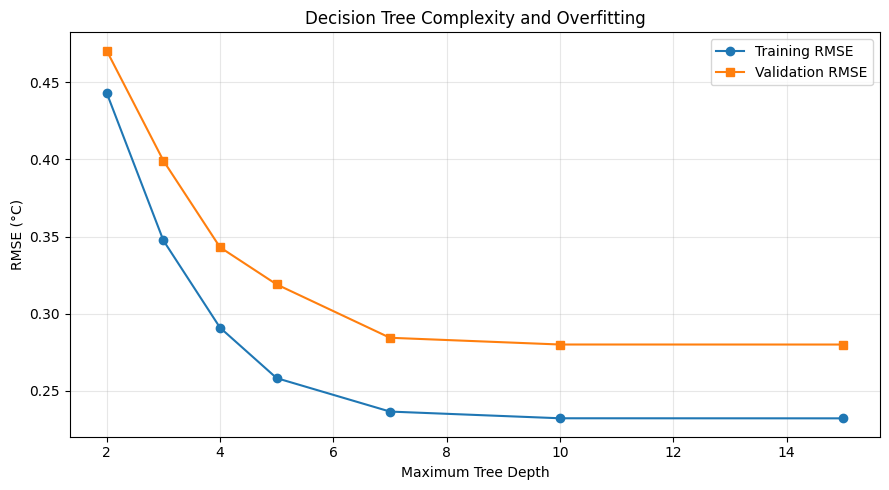

In [46]:
overfitting_results = []

for depth in tree_depths:

    model = DecisionTreeRegressor(
        max_depth=depth,
        min_samples_leaf=5,
        random_state=42
    )

    model.fit(X_train_opt, y_train_opt)

    # Predictions on training and validation data
    train_predictions = model.predict(X_train_opt)
    val_predictions = model.predict(X_val_opt)

    # Calculate RMSE for both datasets
    train_rmse = np.sqrt(
        mean_squared_error(y_train_opt, train_predictions)
    )

    val_rmse = np.sqrt(
        mean_squared_error(y_val_opt, val_predictions)
    )

    overfitting_results.append({
        "Max Depth": depth,
        "Training RMSE (°C)": train_rmse,
        "Validation RMSE (°C)": val_rmse
    })

overfitting_df = pd.DataFrame(overfitting_results)

display(overfitting_df.round(4))

# Visualise training and validation error
plt.figure(figsize=(9, 5))

plt.plot(
    overfitting_df["Max Depth"],
    overfitting_df["Training RMSE (°C)"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    overfitting_df["Max Depth"],
    overfitting_df["Validation RMSE (°C)"],
    marker="s",
    label="Validation RMSE"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("RMSE (°C)")
plt.title("Decision Tree Complexity and Overfitting")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [47]:
#Final model comparison

# Combine training and validation observations
combined_train = pd.concat(
    [train_final, val_final]
).sort_values("timestamp")

# Keep the final test period separate
final_test = test_final.copy()

# Define inputs and targets
X_train = combined_train[feature_columns]
y_train = combined_train["target_temperature_C"]

X_test = final_test[feature_columns]
y_test = final_test["target_temperature_C"]

# Models selected for comparison
models = {
    "Simple Linear Regression": LinearRegression(),
    "Historical Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=best_depth,
        min_samples_leaf=5,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
}

results = []

# Persistence baseline
baseline_predictions = final_test["temperature_C"]

results.append({
    "Model": "Persistence",
    "MAE (°C)": mean_absolute_error(y_test, baseline_predictions),
    "RMSE (°C)": np.sqrt(mean_squared_error(y_test, baseline_predictions)),
    "Training Time (s)": 0.0
})

# Train and evaluate each model
for name, model in models.items():

    if name == "Simple Linear Regression":
        training_inputs = combined_train[["temperature_C"]]
        testing_inputs = final_test[["temperature_C"]]
    else:
        training_inputs = X_train
        testing_inputs = X_test

    start = time.perf_counter()
    model.fit(training_inputs, y_train)
    training_time = time.perf_counter() - start

    predictions = model.predict(testing_inputs)

    results.append({
        "Model": name,
        "MAE (°C)": mean_absolute_error(y_test, predictions),
        "RMSE (°C)": np.sqrt(mean_squared_error(y_test, predictions)),
        "Training Time (s)": training_time
    })

final_results = pd.DataFrame(results)

display(final_results.round(4))

,Model,MAE (°C),RMSE (°C),Training Time (s)
0,Persistence,0.2036,0.4008,0.0000
1,Simple Linear Regression,0.2213,0.3954,0.0025
2,Historical Linear Regression,0.1984,0.3272,0.0027
3,Decision Tree,0.1739,0.2975,0.0061
4,Random Forest,0.1725,0.2917,0.3832


In [53]:

# Calculate intervals between consecutive readings
intervals_0869 = (
    sensor_0869["timestamp"]
    .diff()
    .dt.total_seconds()
    .div(60)
    .dropna()
)

print("\nSampling interval statistics:")
print(intervals_0869.describe())

print("\nGaps greater than 30 minutes:",
      (intervals_0869 > 30).sum())

print("\nIntervals approximately 10 minutes:",
      intervals_0869.between(9.5, 10.5).sum())

print("Intervals approximately 20 minutes:",
      intervals_0869.between(19.5, 20.5).sum())



Sampling interval statistics:
count    13799.000000
mean        11.008102
std          3.013253
min          9.566667
25%         10.000000
50%         10.000000
75%         10.000000
max         29.983333
Name: timestamp, dtype: float64

Gaps greater than 30 minutes: 0

Intervals approximately 10 minutes: 12409
Intervals approximately 20 minutes: 1389


:DEBUGGING, LAST CHAT NOT COMPLETED, CHANGE LAST CELL